# 05b · Priorisation des incidents

**Date :** 5 novembre 2026

**Ce qui est fait :** on classe les incidents du plus urgent au moins urgent, puis on fixe combien d'incidents l'analyste et les agents liront en premier.

**Pourquoi :** le notebook 05 donne 487 incidents sur test_inconnu, dont 474 sans attaque. Dans l'ordre d'arrivée, l'analyste perdrait son temps sur les fausses alertes.

**Règles fixées avant de mesurer sur les tests :**
- **Quatre scores candidats**, sans vraie étiquette ni IP source : `nb_flux`, `score_max` et `score_moyen` (score de l'autoencodeur), `rang_combine` (moyenne du rang par `nb_flux` et du rang par `score_max`).
- **Pas de score basé sur le RF.** Val ne contient que des attaques connues du RF : un tel score y serait avantagé, et ce choix ne dirait rien des attaques inconnues.
- **Critère de choix, sur val :** le moins d'incidents à lire pour voir toutes les attaques au moins une fois. En cas d'égalité, le plus petit rang moyen de première vue.
- **Budget de lecture :** la part des incidents de val nécessaire avec le score retenu, appliquée à chaque ensemble de test.
- **Égalités :** on compte toujours le rang le plus défavorable.
- **Tests :** seuls le score retenu et l'ordre d'arrivée (référence) y sont mesurés, une seule fois. Rien n'est changé ensuite (règle 7).

**Limite à annoncer :** l'idée de regarder la taille des incidents vient de l'observation 6 du notebook 05, faite sur test_inconnu. L'idée n'a donc pas été trouvée sur val seule. Le score et le budget, eux, sont choisis sur val uniquement.

In [1]:
import json
import math
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import LABEL, BENIGN, ROOT
from isocrates.ml.supervised import load_sets, load_model, save_model, signed_log, MODELS, PROCESSED
from isocrates.ml.anomaly import Autoencoder, reconstruction_error
from isocrates.ml.fusion import fuse, number_incidents, summarize_incident
from isocrates.ml.priority import (CANDIDATES, incident_table, worst_rank, add_scores, chronological_rank,
                                   first_rank_by_class, reading_summary, attacks_seen_within)

REPORTS = ROOT / "reports"
INCIDENTS_DIR = PROCESSED / "incidents"

# À cette étape, on ne charge QUE val : les tests ne peuvent pas influencer le choix
sets, features = load_sets(("val",))
val = sets["val"]

rf = load_model("rf")
meta = load_model("autoencoder_meta")
threshold = meta["threshold"]
autoencoder = Autoencoder(len(features), meta["latent_size"])
autoencoder.load_state_dict(torch.load(MODELS / "autoencoder.pt"))

<All keys matched successfully>

## 1. Les incidents de val

Le notebook 05 n'a exporté que les incidents des tests. On construit ceux de val avec exactement le même code, sans les explications, inutiles au score.

In [2]:
X_val = val[features].to_numpy(np.float32)
Z_val = meta["scaler"].transform(signed_log(X_val))

rf_probabilities = rf.predict_proba(X_val)
rf_positions = rf_probabilities.argmax(axis=1)
val["rf_label"] = rf.classes_[rf_positions]
val["rf_proba"] = rf_probabilities.max(axis=1)
val["ae_score"] = reconstruction_error(autoencoder, Z_val)
val["final"], val["source"] = fuse(val["rf_label"].to_numpy(), val["ae_score"].to_numpy(), threshold)

val_alerts = number_incidents(val[val["final"] != BENIGN])

val_incidents = []
val_truth = {}
for number, flows in val_alerts.groupby("incident"):
    incident_id = "INC-val-" + str(int(number)).zfill(4)
    val_incidents.append(summarize_incident(incident_id, flows, threshold))
    val_truth[incident_id] = {}
    for label, count in flows[LABEL].value_counts().items():
        val_truth[incident_id][str(label)] = int(count)

val_table = add_scores(incident_table(val_incidents, val_truth))
print("Incidents de val :", len(val_table), "· avec attaque :", int(val_table["avec_attaque"].sum()))

# Les incidents avec attaque, avec leur vérité. Il y en a très peu : le choix reposera sur eux.
attack_rows = val_table[val_table["avec_attaque"]][["nb_flux", "score_max", "score_moyen"]].copy()
truth_texts = []
for incident_id in attack_rows.index:
    truth_texts.append(str(val_truth[incident_id]))
attack_rows["vérité"] = truth_texts
attack_rows

Incidents de val : 197 · avec attaque : 7


,nb_flux,score_max,score_moyen,vérité
id,,,,
INC-val-0001,600,0.3883,0.3599,{'ftp_patator': 600}
INC-val-0002,444,0.3083,0.2834,{'ssh_patator': 444}
INC-val-0004,851,1.9825,1.3557,{'dos_slowloris': 851}
INC-val-0005,601,1.7258,0.4748,{'dos_slowhttptest': 601}
INC-val-0006,23848,1.2592,0.3023,{'dos_hulk': 23848}
INC-val-0007,1015,0.5301,0.2022,{'dos_goldeneye': 1015}
INC-val-0011,2,0.8797,0.8429,{'heartbleed': 2}


In [3]:
# Les incidents sans attaque, pour comparer
val_table[~val_table["avec_attaque"]][["nb_flux", "score_max", "score_moyen"]].describe().round(2)

,nb_flux,score_max,score_moyen
count,190.00,190.00,190.00
mean,7.90,0.55,0.37
std,15.08,0.49,0.21
min,1.00,0.13,0.13
25%,1.00,0.28,0.25
50%,3.00,0.44,0.31
75%,7.00,0.64,0.43
max,114.00,5.35,1.59


## 2. Choix du score, sur val

On applique le critère fixé plus haut. L'ordre d'arrivée sert de référence : c'est ce que ferait un analyste sans priorisation.

In [4]:
rows = []
reference = reading_summary(chronological_rank(val_table), val_truth)
reference["score"] = "ordre d'arrivée (référence)"
rows.append(reference)

for candidate in CANDIDATES:
    ranks = worst_rank(val_table[candidate])
    summary = reading_summary(ranks, val_truth)
    summary["score"] = candidate
    rows.append(summary)

val_comparison = pd.DataFrame(rows).set_index("score")
val_comparison

/home/bedis/miniconda3/envs/isocrates/lib/python3.11/site-packages/pyarrow/compute.py:231: FutureWarning: Specifying null_placement in RankOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)


,incidents à lire pour voir toutes les attaques,rang moyen de la première vue
score,,
ordre d'arrivée (référence),193,133.4
nb_flux,142,23.3
score_max,138,53.7
score_moyen,180,75.1
rang_combine,75,30.4


In [5]:
# Application du critère : le moins d'incidents à lire, puis le plus petit rang moyen
retained = None
best_needed = None
best_mean = None
for candidate in CANDIDATES:
    needed = val_comparison.loc[candidate, "incidents à lire pour voir toutes les attaques"]
    mean_rank = val_comparison.loc[candidate, "rang moyen de la première vue"]
    is_better = retained is None or needed < best_needed or (needed == best_needed and mean_rank < best_mean)
    if is_better:
        retained = candidate
        best_needed = needed
        best_mean = mean_rank
print("Score retenu :", retained, "·", int(best_needed), "incidents à lire sur", len(val_table))

Score retenu : rang_combine · 75 incidents à lire sur 197


In [6]:
# Détail par attaque : rang du premier incident qui la contient
details = {"ordre d'arrivée": first_rank_by_class(chronological_rank(val_table), val_truth)}
for candidate in CANDIDATES:
    details[candidate] = first_rank_by_class(worst_rank(val_table[candidate]), val_truth)
pd.DataFrame(details)

/home/bedis/miniconda3/envs/isocrates/lib/python3.11/site-packages/pyarrow/compute.py:231: FutureWarning: Specifying null_placement in RankOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)


,ordre d'arrivée,nb_flux,score_max,score_moyen,rang_combine
dos_goldeneye,147,2,65,180,22
dos_hulk,146,1,12,106,4
dos_slowhttptest,145,4,6,35,3
dos_slowloris,144,3,3,3,1
ftp_patator,69,5,119,77,49
heartbleed,193,142,33,8,75
ssh_patator,90,6,138,117,59


In [7]:
# Sensibilité : heartbleed n'a que 2 flux. Que devient le classement sans lui ?
truth_without = {}
for incident_id, incident_truth in val_truth.items():
    truth_without[incident_id] = {}
    for label, count in incident_truth.items():
        if label != "heartbleed":
            truth_without[incident_id][label] = count

rows = []
for candidate in CANDIDATES:
    summary = reading_summary(worst_rank(val_table[candidate]), truth_without)
    summary["score"] = candidate
    rows.append(summary)
print("Sans heartbleed (lecture seulement : le choix ne change pas)")
pd.DataFrame(rows).set_index("score")

Sans heartbleed (lecture seulement : le choix ne change pas)


,incidents à lire pour voir toutes les attaques,rang moyen de la première vue
score,,
nb_flux,6,3.5
score_max,138,57.2
score_moyen,180,86.3
rang_combine,59,23.0


## 3. Budget de lecture, sur val

Le budget est une **part** des incidents : le nombre d'incidents n'est pas le même d'un ensemble à l'autre. On arrondit au-dessus pour ne pas couper juste avant le dernier incident utile.

In [8]:
budget_share = best_needed / len(val_table)
print("Part retenue :", round(100 * budget_share, 1), "% des incidents")


def budget_for(n_incidents):
    """Nombre d'incidents à lire en premier, pour un ensemble de n_incidents incidents."""
    return math.ceil(budget_share * n_incidents)


# On fige le choix AVANT de charger les tests
save_model({"score": retained, "part_budget": float(budget_share)}, "priority_choice")

Part retenue : 38.1 % des incidents


## 4. Mesure unique sur test_connu et test_inconnu

Le score et le budget sont figés. Les incidents viennent des fichiers du notebook 05. La vérité ne sert qu'à l'évaluation.

In [9]:
def load_incidents(set_name):
    """Lit les incidents du notebook 05, et la vérité rangée à part."""
    with open(INCIDENTS_DIR / (set_name + ".json"), encoding="utf-8") as f:
        content = json.load(f)
    with open(INCIDENTS_DIR / ("verite_" + set_name + ".json"), encoding="utf-8") as f:
        truth = json.load(f)
    return content, truth


contents = {}
truths = {}
tables = {}
ranks = {}
chrono_ranks = {}
budgets = {}
for set_name in ["test_connu", "test_inconnu"]:
    contents[set_name], truths[set_name] = load_incidents(set_name)
    tables[set_name] = add_scores(incident_table(contents[set_name]["incidents"], truths[set_name]))
    ranks[set_name] = worst_rank(tables[set_name][retained])
    chrono_ranks[set_name] = chronological_rank(tables[set_name])
    budgets[set_name] = budget_for(len(tables[set_name]))

/home/bedis/miniconda3/envs/isocrates/lib/python3.11/site-packages/pyarrow/compute.py:231: FutureWarning: Specifying null_placement in RankOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)
/home/bedis/miniconda3/envs/isocrates/lib/python3.11/site-packages/pyarrow/compute.py:231: FutureWarning: Specifying null_placement in RankOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)


In [10]:
def budget_summary(set_name):
    """Ce que contient le budget, avec le score retenu et avec l'ordre d'arrivée."""
    table = tables[set_name]
    budget = budgets[set_name]
    rows = []
    orders = {"score retenu": ranks[set_name], "ordre d'arrivée": chrono_ranks[set_name]}
    for order_name, order_ranks in orders.items():
        inside = table[order_ranks <= budget]
        n_real = int(inside["avec_attaque"].sum())
        all_attacks = first_rank_by_class(order_ranks, truths[set_name])
        seen = attacks_seen_within(order_ranks, truths[set_name], budget)
        rows.append({
            "ensemble": set_name,
            "ordre": order_name,
            "incidents": len(table),
            "budget": budget,
            "lus (égalités comprises)": len(inside),
            "avec attaque lus": n_real,
            "avec attaque en tout": int(table["avec_attaque"].sum()),
            "sans attaque lus": len(inside) - n_real,
            "classes vues": len(seen),
            "classes en tout": len(all_attacks),
            "à lire pour tout voir": int(all_attacks.max()),
        })
    return rows


summary_rows = budget_summary("test_connu") + budget_summary("test_inconnu")
pd.DataFrame(summary_rows).set_index(["ensemble", "ordre"]).T

ensemble                   test_connu                 test_inconnu  \
ordre                    score retenu ordre d'arrivée score retenu   
incidents                         239             239          487   
budget                             91              91          186   
lus (égalités comprises)           90              91          185   
avec attaque lus                    7               2           13   
avec attaque en tout                7               7           13   
sans attaque lus                   83              89          172   
classes vues                        7               2            6   
classes en tout                     7               7            6   
à lire pour tout voir              85             142          121   

ensemble                                  
ordre                    ordre d'arrivée  
incidents                            487  
budget                               186  
lus (égalités comprises)             186  
avec attaque lus                       3  
avec attaque en tout                  13  
sans attaque lus                     183  
classes vues                           4  
classes en tout                        6  
à lire pour tout voir                442

In [11]:
# Par attaque : rang du premier incident qui la contient
for set_name in ["test_connu", "test_inconnu"]:
    by_class = pd.DataFrame({
        "score retenu": first_rank_by_class(ranks[set_name], truths[set_name]),
        "ordre d'arrivée": first_rank_by_class(chrono_ranks[set_name], truths[set_name]),
    })
    by_class["dans le budget"] = by_class["score retenu"] <= budgets[set_name]
    print(set_name, "· budget :", budgets[set_name], "incidents")
    display(by_class)

test_connu · budget : 91 incidents


,score retenu,ordre d'arrivée,dans le budget
dos_goldeneye,4,141,True
dos_hulk,6,140,True
dos_slowhttptest,4,139,True
dos_slowloris,2,138,True
ftp_patator,57,64,True
heartbleed,85,142,True
ssh_patator,16,65,True


test_inconnu · budget : 186 incidents


,score retenu,ordre d'arrivée,dans le budget
bot,4,163,True
ddos,17,442,True
portscan,2,346,True
webattack_bruteforce,121,20,True
webattack_sql_injection,50,60,True
webattack_xss,50,60,True


In [12]:
# Tous les incidents avec attaque de test_inconnu, du plus urgent au moins urgent
table = tables["test_inconnu"].copy()
table["rang"] = ranks["test_inconnu"]
real_incidents = table[table["avec_attaque"]].sort_values("rang")[["rang", "nb_flux", "score_max"]].copy()
truth_texts = []
for incident_id in real_incidents.index:
    truth_texts.append(str(truths["test_inconnu"][incident_id]))
real_incidents["vérité"] = truth_texts
real_incidents

,rang,nb_flux,score_max,vérité
id,,,,
INC-test_inconnu-0015,2,11383,5.4050,"{'portscan': 11096, 'benign': 287}"
INC-test_inconnu-0014,2,139586,5.1383,"{'portscan': 139585, 'benign': 1}"
INC-test_inconnu-0016,3,9079,5.4035,"{'portscan': 9076, 'benign': 3}"
INC-test_inconnu-0102,4,402,2.2238,"{'benign': 233, 'bot': 169}"
INC-test_inconnu-0012,8,157,1.6981,"{'portscan': 118, 'benign': 39}"
INC-test_inconnu-0330,13,204,1.0934,"{'benign': 125, 'bot': 79}"
INC-test_inconnu-0017,17,95726,1.0152,"{'ddos': 95683, 'benign': 43}"
INC-test_inconnu-0451,33,281,0.8502,"{'benign': 150, 'bot': 131}"
INC-test_inconnu-0080,41,125,0.7618,"{'bot': 100, 'benign': 25}"


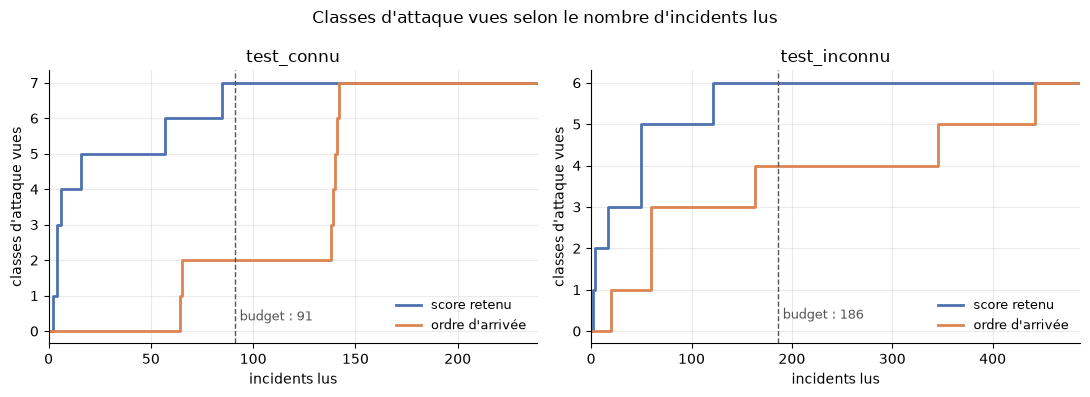

In [13]:
def classes_seen_curve(order_ranks, truth):
    """Rangs triés de première vue : la courbe monte d'une classe à chacun de ces rangs."""
    return np.sort(first_rank_by_class(order_ranks, truth).to_numpy())


fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, set_name in zip(axes, ["test_connu", "test_inconnu"]):
    n_incidents = len(tables[set_name])
    curves = [
        ("score retenu", ranks[set_name], "#4C72B0"),
        ("ordre d'arrivée", chrono_ranks[set_name], "#DD8452"),
    ]
    for curve_name, order_ranks, color in curves:
        seen_at = classes_seen_curve(order_ranks, truths[set_name])
        x_values = np.concatenate(([0], seen_at, [n_incidents]))
        y_values = np.concatenate(([0], np.arange(1, len(seen_at) + 1), [len(seen_at)]))
        ax.step(x_values, y_values, where="post", linewidth=2, color=color, label=curve_name)
    ax.axvline(budgets[set_name], color="#555555", linestyle="--", linewidth=1)
    ax.text(budgets[set_name] + n_incidents * 0.01, 0.3, "budget : " + str(budgets[set_name]), fontsize=9, color="#555555")
    ax.set_xlim(0, n_incidents)
    ax.set_xlabel("incidents lus")
    ax.set_ylabel("classes d'attaque vues")
    ax.set_title(set_name)
    ax.grid(alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(fontsize=9, loc="lower right", frameon=False)
fig.suptitle("Classes d'attaque vues selon le nombre d'incidents lus")
fig.tight_layout()
fig.savefig(REPORTS / "05b_classes_vues.png", dpi=150)
plt.show()

## 5. Export

`data/processed/incidents/{test_connu,test_inconnu}_priorise.json` : les incidents triés, avec `rang_priorite` et `dans_budget`. La vraie étiquette n'y entre pas. Les fichiers du notebook 05 ne changent pas.

In [14]:
def get_priority_rank(incident):
    """Clé de tri : le rang de priorité de l'incident."""
    return incident["rang_priorite"]


for set_name in contents:
    ordered = []
    for incident in contents[set_name]["incidents"]:
        rank = int(ranks[set_name][incident["id"]])
        incident_copy = dict(incident)
        incident_copy["rang_priorite"] = rank
        incident_copy["dans_budget"] = rank <= budgets[set_name]
        assert LABEL not in incident_copy and "verite" not in incident_copy
        ordered.append(incident_copy)
    # Python trie de façon stable : à rang égal, l'ordre d'origine est gardé
    ordered.sort(key=get_priority_rank)

    new_content = dict(contents[set_name])
    new_content["priorisation"] = {"score": retained, "part_budget": round(float(budget_share), 4), "budget": budgets[set_name]}
    new_content["incidents"] = ordered
    path = INCIDENTS_DIR / (set_name + "_priorise.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(new_content, f, indent=2, ensure_ascii=False)
    print(set_name, ":", len(ordered), "incidents écrits dans", path.name)

test_connu : 239 incidents écrits dans test_connu_priorise.json
test_inconnu : 487 incidents écrits dans test_inconnu_priorise.json


## Observations

1. **Le critère de val retient `rang_combine`.** Il faut lire 75 incidents sur 197 pour voir les 7 attaques de val, contre 142 avec `nb_flux`, 138 avec `score_max`, 180 avec `score_moyen` et 193 dans l'ordre d'arrivée. Le budget vaut donc 38,1 % des incidents.
2. **Ce choix est fragile, car il dépend d'une seule classe.** Val ne contient que 7 incidents avec attaque, et heartbleed (2 flux) décide du résultat. Sans heartbleed, `nb_flux` suffirait avec 6 incidents, contre 59 pour `rang_combine`. Le critère fixé à l'avance est gardé : il protège les petites attaques, que la taille seule classe très bas (heartbleed au rang 142).
3. **Sur test_inconnu, les 13 incidents avec attaque sont dans le budget, et les 6 classes sont vues.** Le budget de 186 conduit à lire 185 incidents, car les égalités comptent au rang le plus défavorable. Le dernier incident avec attaque est au rang 121, contre 442 dans l'ordre d'arrivée pour voir toutes les classes. Dans l'ordre d'arrivée, le même budget ne contient que 3 incidents avec attaque et 4 classes sur 6.
4. **Sur test_connu, les 7 incidents avec attaque sont aussi dans le budget.** Il faut lire 85 incidents pour tout voir, contre 142 dans l'ordre d'arrivée, avec un budget de 91 (90 lus). La marge est faible, et heartbleed arrive encore en dernier.
5. **La charge baisse, mais les fausses alertes restent majoritaires.** Sur test_inconnu, on passe de 487 à 185 incidents à lire (−62 %) et de 474 à 172 incidents sans attaque. La part d'incidents avec attaque passe de 2,7 % à 7,0 % : **93 % de ce qui est lu reste une fausse alerte.** La priorisation réduit le problème sans le régler. Sur test_connu : 83 incidents sans attaque sur 90 lus.
6. **Les attaques web restent tardives.** Les 7 incidents avec attaque des 17 premiers rangs de test_inconnu ne couvrent que portscan, bot et DDoS. XSS et sql_injection (un même incident) sont au rang 50, bruteforce au rang 121, Un budget beaucoup plus court les perdrait.
7. **« Voir » un incident ne veut pas dire reconnaître l'attaque.** 12 des 13 incidents avec attaque de test_inconnu sont mixtes, et leur nom vient souvent d'un RF qui ne connaît pas ces attaques. C'est le travail des agents, à mesurer dans le notebook 08.
8. **Limites à citer dans le rapport.** L'idée de regarder la taille vient d'une observation faite sur test_inconnu (notebook 05). Le classement se calcule sur tous les incidents d'un ensemble, donc après coup, pas en temps réel. Les détections viennent d'un seul entraînement, alors que bot est instable. Enfin, val ne contient que des attaques connues, alors que le score est utilisé sur des attaques inconnues.
9. **Les autres scores n'ont pas été mesurés sur les tests.** On ne peut donc pas dire si `nb_flux` y aurait fait mieux, et on ne cherche pas à le savoir : le comparer maintenant inciterait à changer de choix (règle 7).